# The Godot editor as your toolbox

**The idea:** the Godot editor is not a fixed program you put up with. It is a Godot app, built from the same nodes you already use, and you can add to it.

**Why it matters for you:** content making is the slow part of the cycle. Every editor tool you add makes the *data dev* (also you) faster and less able to make mistakes.

Companion to `data-driven-design-in-godot.ipynb` (same folder). That one is about *what* to author as data; this one is about *shaping the editor* so authoring is quick.

| Section | Question it answers |
|---|---|
| 1 | What is the editor, really? |
| 2 | What are the two hats (code dev, data dev)? |
| 3 | What can I customise, cheapest first? |
| 4 | Which of these do I already use in this repo? |
| 5 | Where on screen can a plugin put things? |
| 6 | How do I talk to the editor from code? |
| 7 | How do I figure out a new trick on my own? |
| 8 | What bites people? |
| 9 | "I keep doing X by hand": which tool fixes it? |
| 10 | What should I practise first? |


## 1. The editor is a Godot app

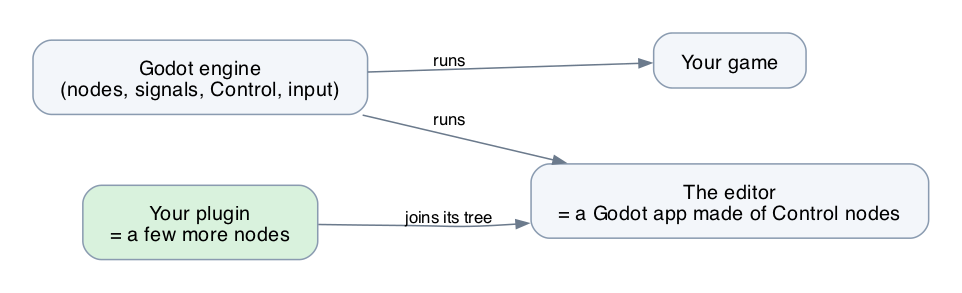

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  engine [label="Godot engine\n(nodes, signals, Control, input)"];
  editor [label="The editor\n= a Godot app made of Control nodes"];
  game   [label="Your game"];
  plugin [label="Your plugin\n= a few more nodes", fillcolor="#d9f2dd"];
  engine -> editor [label="runs"];
  engine -> game   [label="runs"];
  plugin -> editor [label="joins its tree"];
}
```

</details>

Yes, you heard right: the editor is made with the engine itself. The Inspector, the docks, the script editor are all `Control` nodes in one big scene tree.

| Because the editor is a Godot app... | ...this works |
|---|---|
| It is a tree of nodes | A plugin is a node; `_enter_tree` / `_exit_tree` are when it loads / unloads |
| Its UI is `Control` nodes | You build editor UI the way you build a game menu (even as a `.tscn`) |
| It gets input like a game | `_input` in a plugin catches keys (your Cmd+Option+L copy shortcut) |
| It uses signals | You can connect to "selection changed", "scene saved", "file moved"... |

**Mental shift:** you are not "configuring an IDE". You are adding nodes to a running Godot scene.


### Feel it: a toy editor in 15 lines

Not real Godot, just the shape of it. The editor is a tree; a plugin adds a branch.


In [1]:
class Node:
	def __init__(self, name): self.name, self.children = name, []
	def add_child(self, node): self.children.append(node); return node
	def show(self, depth=0):
		print("  " * depth + self.name)
		for child in self.children: child.show(depth + 1)

# the editor, as shipped
editor = Node("Editor")
docks = editor.add_child(Node("Docks"))
docks.add_child(Node("Scene"))
docks.add_child(Node("Inspector"))
editor.add_child(Node("MainScreen (2D / 3D / Script)"))
bottom = editor.add_child(Node("BottomPanel"))
bottom.add_child(Node("Output"))

# your plugin: just more nodes
bottom.add_child(Node("_rpgm_v1  <- your panel"))
docks.add_child(Node("@icons  <- a dock from an addon"))

editor.show()

Editor
  Docks
    Scene
    Inspector
    @icons  <- a dock from an addon
  MainScreen (2D / 3D / Script)
  BottomPanel
    Output
    _rpgm_v1  <- your panel


In [2]:
# ----- student scratchpad ----- 

## 2. Two hats: code dev and data dev

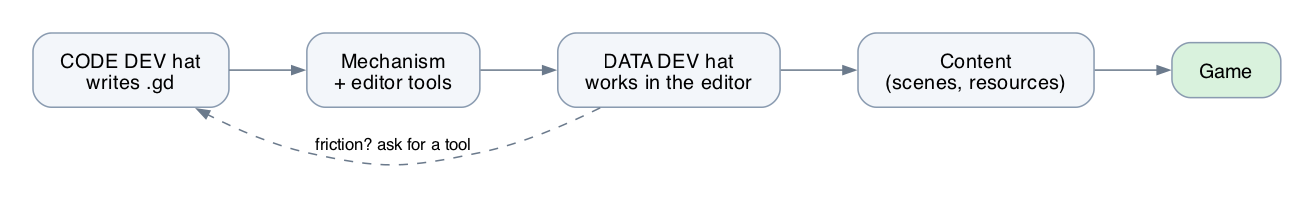

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  code  [label="CODE DEV hat\nwrites .gd"];
  tools [label="Mechanism\n+ editor tools"];
  data  [label="DATA DEV hat\nworks in the editor"];
  content [label="Content\n(scenes, resources)"];
  game  [label="Game", fillcolor="#d9f2dd"];
  code -> tools -> data -> content -> game;
  data -> code [label="friction? ask for a tool", style=dashed, constraint=false];
}
```

</details>

| | Code dev | Data dev |
|---|---|---|
| Works in | `.gd` files | Scene tree, Inspector, resources |
| Produces | Mechanism **and editor tools** | Content |
| Their bug | **Code bug** (mech bug) | **Data bug** (content bug) |
| Good day looks like | Data dev never has to open a script | Lots of content, no surprises |

The editor is where the two hats meet. The code dev's real customer is the data dev.

**The habit to build:** when you are wearing the data hat and something is annoying, repeated, or easy to get wrong, stop and switch hats. That annoyance is a tool waiting to be written.

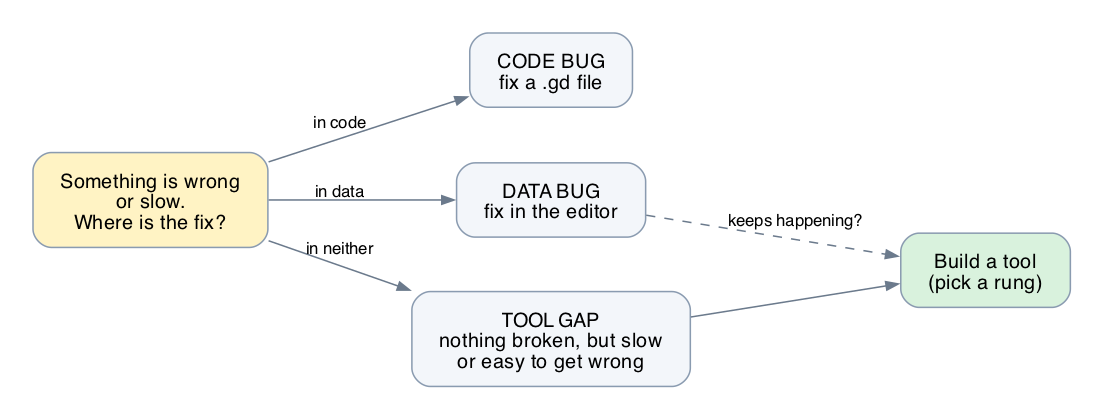

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  q [label="Something is wrong\nor slow.\nWhere is the fix?", fillcolor="#fff3c4"];
  codebug [label="CODE BUG\nfix a .gd file"];
  databug [label="DATA BUG\nfix in the editor"];
  gap [label="TOOL GAP\nnothing broken, but slow\nor easy to get wrong"];
  tool [label="Build a tool\n(pick a rung)", fillcolor="#d9f2dd"];
  q -> codebug [label="in code"];
  q -> databug [label="in data"];
  q -> gap [label="in neither"];
  gap -> tool;
  databug -> tool [label="keeps happening?", style=dashed];
}
```

</details>

"Tool gap" is my suggested third word, next to your code bug and data bug: nothing is broken, the editor just isn't helping yet.


## 3. The ladder: cheapest customisation first

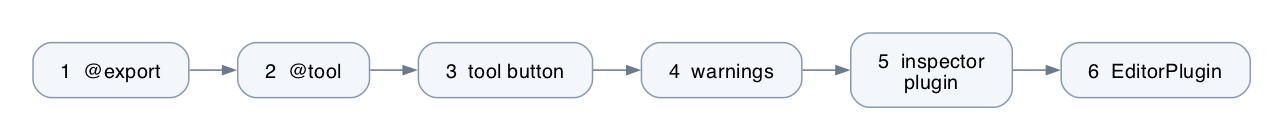

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  nodesep=0.3; ranksep=0.45;
  a [label="1  @export"];
  b [label="2  @tool"];
  c [label="3  tool button"];
  d [label="4  warnings"];
  e [label="5  inspector\nplugin"];
  f [label="6  EditorPlugin"];
  a -> b -> c -> d -> e -> f;
}
```

</details>

Always try the lowest rung that solves the problem.

| Rung | What you write | What the data dev gets | Effort |
|---|---|---|---|
| 1 | `@export` (plus enums, ranges, groups) | A typed field in the Inspector | 1 line |
| 2 | `@tool` at the top of a script | The script runs **inside the editor**, so the scene previews live | 1 line + care |
| 3 | `@export_tool_button` | A button in the Inspector that runs a function | 1 line |
| 4 | `_get_configuration_warnings()` | A yellow warning triangle on a badly set-up node | ~5 lines |
| 5 | `EditorInspectorPlugin` | Custom layout or widgets inside the Inspector | 1 small file |
| 6 | `EditorPlugin` | Anything: docks, panels, menus, shortcuts, drawing on the 2D view | An addon folder |

Off to the side of the ladder:

| Tool | Use it for |
|---|---|
| `EditorScript` | A one-off job you run by hand (File > Run in the script editor): batch-fix 50 scenes, find bad data |
| `_get_property_list()` / `_validate_property()` | Fields that appear, hide or change depending on other fields |


## 4. What you already use

You are further up the ladder than you might think. Run this to scan the repo (it only reads files).


In [3]:
import os, re

# find the repo root (the folder holding project.godot)
root = os.getcwd()
while not os.path.exists(os.path.join(root, "project.godot")) and root != "/":
	root = os.path.dirname(root)

RUNGS = [
	("1  @export",                r"^\s*@export(?!_tool_button)"),
	("2  @tool",                  r"^@tool"),
	("3  @export_tool_button",    r"@export_tool_button"),
	("4  config warnings",        r"func _get_configuration_warnings"),
	("5  EditorInspectorPlugin",  r"^extends EditorInspectorPlugin"),
	("6  EditorPlugin",           r"^extends EditorPlugin"),
	("-  EditorScript",           r"^extends EditorScript"),
	("-  dynamic properties",     r"func (_get_property_list|_validate_property)"),
]
SKIP = (".godot", "build", "addons/at-icons", "other/docs")   # caches, third-party, docs

files = []
for folder, _, names in os.walk(root):
	rel = os.path.relpath(folder, root)
	if any(rel == s or rel.startswith(s + os.sep) for s in SKIP): continue
	files += [os.path.join(folder, n) for n in names if n.endswith(".gd")]

print(f"{'rung':<26}{'uses':>5}{'files':>7}   example")
for label, pattern in RUNGS:
	uses, hits = 0, []
	for path in files:
		n = len(re.findall(pattern, open(path, errors="ignore").read(), re.M))
		if n: uses += n; hits.append(os.path.relpath(path, root))
	print(f"{label:<26}{uses:>5}{len(hits):>7}   {hits[0] if hits else '(not used yet)'}")

rung                       uses  files   example
1  @export                   50     21   core/_core_portrait.gd
2  @tool                     15     15   tools/batch_rpgmaker_tile_converter.gd
3  @export_tool_button        3      3   viewports/dgm/_dgm_tilemap.gd
4  config warnings            0      0   (not used yet)
5  EditorInspectorPlugin      1      1   addons/_rpgm_v1/mover_inspector_plugin.gd
6  EditorPlugin               2      2   addons/_rpgm_v1/plugin.gd
-  EditorScript               2      2   tools/batch_rpgmaker_tile_converter.gd
-  dynamic properties         1      1   viewports/rpgm/components/_rpgm_portrait.gd


In [4]:
# ----- student scratchpad ----- 

Your three addons, and which editor hook each one uses:

| Addon | What it does | Hook |
|---|---|---|
| `addons/_rpgm_v1` | Bottom panel + the one-row quantise buttons on `_RPGM_Mover` | `add_control_to_bottom_panel`, `add_inspector_plugin` |
| `addons/copy_with_path` | Cmd+Option+L copies lines with path and line numbers | `_input` + `EditorInterface.get_script_editor()` |
| `addons/at-icons` (third-party) | Icon browser dock | `add_dock(EditorDock)` |

Reading these three files top to bottom is the fastest lesson available: each is under 60 lines and each shows a different hook.


## 5. Where a plugin can put things

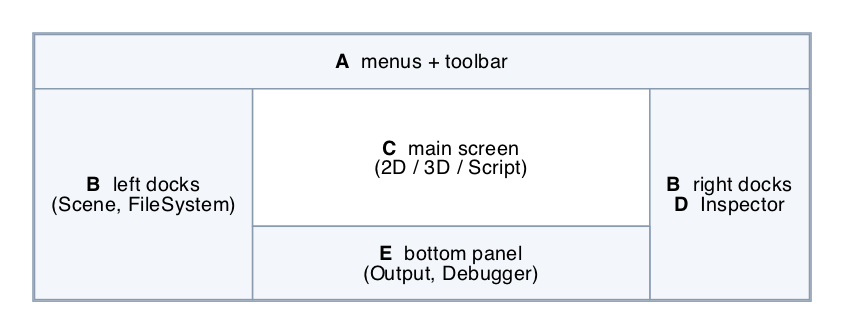

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  node [shape=plain, style="", fontname="Helvetica", fontsize=13];
  m [label=<
    <table border="1" cellborder="1" cellspacing="0" cellpadding="10" color="#8a9bb0">
      <tr><td colspan="3" bgcolor="#f3f6fa"><b>A</b>  menus + toolbar</td></tr>
      <tr>
        <td rowspan="2" bgcolor="#f3f6fa"><b>B</b>  left docks<br/>(Scene, FileSystem)</td>
        <td bgcolor="#ffffff" width="260" height="90"><b>C</b>  main screen<br/>(2D / 3D / Script)</td>
        <td rowspan="2" bgcolor="#f3f6fa"><b>B</b>  right docks<br/><b>D</b>  Inspector</td>
      </tr>
      <tr><td bgcolor="#f3f6fa"><b>E</b>  bottom panel<br/>(Output, Debugger)</td></tr>
    </table>>];
}
```

</details>

| Spot | What goes there | `EditorPlugin` call |
|---|---|---|
| **A** menus | An entry under Project > Tools | `add_tool_menu_item` |
| **A** toolbar | A button next to the 2D tools | `add_control_to_container` |
| **B** docks | A side panel like Scene or FileSystem | `add_dock` |
| **C** main screen | A whole new tab next to 2D / 3D / Script | `_has_main_screen` + `_get_plugin_name` |
| **C** 2D view | Draw guides over the scene, catch clicks in it | `_forward_canvas_draw_over_viewport`, `_forward_canvas_gui_input` |
| **D** Inspector | Custom rows and widgets | `add_inspector_plugin` |
| **E** bottom panel | A wide panel like Output | `add_control_to_bottom_panel` |
| Right-click menus | Extra entries in Scene / FileSystem menus | `add_context_menu_plugin` |
| Keyboard | A shortcut | `_input` or `_shortcut_input` |

All of these names exist in your installed Godot build (I checked the binary). `add_control_to_bottom_panel` is the older style; `EditorDock` is the newer one and I believe it can also target the bottom, so check F1 before writing new panels.

**Rule:** whatever you add in `_enter_tree`, remove in `_exit_tree`.


## 6. `EditorInterface`: the remote control

One global object that lets code ask the editor things and tell it to do things.

| You want | Call |
|---|---|
| The nodes currently selected | `EditorInterface.get_selection().get_selected_nodes()` |
| The root of the open scene | `EditorInterface.get_edited_scene_root()` |
| Show something in the Inspector | `EditorInterface.inspect_object(thing)` |
| Open a scene | `EditorInterface.open_scene_from_path("res://...")` |
| The script editor (current script, caret, selection) | `EditorInterface.get_script_editor()` |
| The project's files | `EditorInterface.get_resource_filesystem()` |
| Editor settings | `EditorInterface.get_editor_settings()` |
| The editor's own root `Control` | `EditorInterface.get_base_control()` |

Most tools are just: **read the selection, loop over nodes, change properties.**


## 7. How to work out a new trick yourself

| Route | How | Good for |
|---|---|---|
| **F1 help** | Search `Editor` in the built-in help | Finding the official hook (`EditorPlugin`, `EditorInterface`, `EditorInspectorPlugin`) |
| **Print the editor's tree** | Run the script below | Seeing that the editor really is nodes, and finding a panel |
| **Read an addon** | Open any addon's `plugin.gd` | Copying a working pattern |
| **Godot source, `editor/` folder** | On GitHub | Last resort: how a built-in panel does it |

Paste this in a new script and run it with **File > Run** in the script editor. I have not run it in your editor, so treat it as a sketch.

```gdscript
@tool
extends EditorScript

func _run() -> void:
	_print_tree(EditorInterface.get_base_control(), 0)

func _print_tree(node: Node, depth: int) -> void:
	if depth > 3: return
	print("  ".repeat(depth), node.name, " (", node.get_class(), ")")
	for child in node.get_children():
		_print_tree(child, depth + 1)
```

Looking is fine. **Don't build tools that depend on those internal node names**: they change between Godot versions. Use the official hooks from section 5.


## 8. Traps

| Trap | What happens | Avoid it by |
|---|---|---|
| `@tool` code runs in the editor | Game logic fires while you edit; can move or delete things in the open scene | Guard with `Engine.is_editor_hint()` (you already do this in the rpgm scripts) |
| Error in a `@tool` script | The node goes dead in the editor until the script is fixed and the scene reloaded | Keep editor-side code small and boring |
| Tool changes skip undo | Cmd+Z does not bring back what a button changed | Go through `EditorUndoRedoManager` (`get_undo_redo()` in a plugin) |
| No cleanup in `_exit_tree` | Duplicate panels and leftovers every time the plugin reloads | Remove everything you added |
| Plugin code edits not showing | You changed `plugin.gd` and nothing happened | Turn the plugin off and on in Project Settings > Plugins |
| `_input` sees every key in the editor | Your shortcut fires in the wrong place | Check what has focus first (copy_with_path checks the code editor) |
| A `@tool` script calls a non-tool script | Errors, or the call does nothing in the editor | Whatever runs in the editor needs `@tool` too |


## 9. "I keep doing X by hand"

| Friction (data hat) | Tool (code hat) | Rung |
|---|---|---|
| I type the same few values over and over | `@export` with an enum or range | 1 |
| I have to run the game to see how it looks | `@tool` so it previews in the editor | 2 |
| I do the same fix-up after placing every node | `@export_tool_button` (your Quantise buttons) | 3 |
| I forget to fill in a field, and find out at runtime | `_get_configuration_warnings()` | 4 |
| The Inspector for this node is long and awkward | `EditorInspectorPlugin` | 5 |
| I need an overview across the whole scene or project | A dock or bottom panel | 6 |
| I need the same edit in 50 scenes, once | `EditorScript` | side |
| I want to check all content for mistakes | `EditorScript` now, a panel button later | side |

Rung 4 is the best value on the list: it turns a silent data bug into a visible one, and the scan in section 4 shows whether you use it yet.


## 10. Practice path

Small, one at a time, each useful on its own.

| Step | Do | You learn |
|---|---|---|
| 1 | Read your three `plugin.gd` files side by side | Three different hooks, in under 150 lines total |
| 2 | Run the tree-printing `EditorScript` from section 7 | The editor is nodes |
| 3 | Add one `_get_configuration_warnings()` to a node you often mis-set | Catching data bugs at edit time |
| 4 | Make one button in the `_rpgm_v1` bottom panel do something real with the current selection | `EditorInterface` + selection |
| 5 | Make that button's change undoable | `EditorUndoRedoManager` |
| 6 | Add a Project > Tools menu entry that runs a whole-project content check | Menus + batch checks |

Two small leftovers I noticed while reading, not changed:

| File | Leftover |
|---|---|
| `addons/_rpgm_v1/plugin.cfg` | Still has the template values `name="My Plugin"`, `author="you"` |
| `addons/copy_with_path/plugin.gd` | Comment says Cmd + Option + C, the key is now L |
